# SIH26009 – Integrated Manganese Mine Intelligence Pipeline

This notebook keeps the original spatial/geological workflow and adds the missing operational intelligence required by the problem statement.

## Main flow

**Load area → Check environment → Check equipment → Check blast delays → Check production target → Predict production/shortfall → Explain risk → Suggest preventive measures → Reserve/prospectivity mapping → Save outputs**

> **Important:** The newly supplied CSVs are synthetic prototype data. Replace them with real MOIL/remote-sensing/operational records for deployment.


In [ ]:
# Core imports
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)
import xgboost as xgb

DATA_DIR = Path(".")
OUTPUT_DIR = DATA_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# One source of truth for the prospectivity threshold.
# This matches the value currently used by the model-finalization script.
PROSPECTIVITY_THRESHOLD = 0.45

def load_csv(name, **kwargs):
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path.resolve()}")
    return pd.read_csv(path, **kwargs)

print("Output directory:", OUTPUT_DIR.resolve())


Output directory: C:\Users\ankit\OneDrive\Desktop\sih use\outputs


## 1. Load the study area

In [2]:
# Prefer the original area source. If it is not present, derive a simple
# study-area polygon from the enhanced 14,400-point reserve grid.
area_source = None

if (DATA_DIR / "synthetic_manganese_drillholes_with_outliers.csv").exists():
    area_df = load_csv("synthetic_manganese_drillholes_with_outliers.csv")
    lon_col = "longitude" if "longitude" in area_df.columns else "lon"
    lat_col = "latitude" if "latitude" in area_df.columns else "lat"
    gdf = gpd.GeoDataFrame(
        area_df,
        geometry=gpd.points_from_xy(area_df[lon_col], area_df[lat_col]),
        crs="EPSG:4326",
    )
    study_area = gpd.GeoDataFrame(
        {"name": ["MOIL prototype study area"]},
        geometry=[gdf.geometry.unary_union.convex_hull],
        crs="EPSG:4326",
    )
    area_source = "synthetic_manganese_drillholes_with_outliers.csv"
else:
    reserve_grid = load_csv("synthetic_reserve_grid_enhanced.csv")
    min_lon, max_lon = reserve_grid["lon"].min(), reserve_grid["lon"].max()
    min_lat, max_lat = reserve_grid["lat"].min(), reserve_grid["lat"].max()

    from shapely.geometry import box
    study_area = gpd.GeoDataFrame(
        {"name": ["MOIL prototype study area"]},
        geometry=[box(min_lon, min_lat, max_lon, max_lat)],
        crs="EPSG:4326",
    )
    area_source = "synthetic_reserve_grid_enhanced.csv (derived bounds)"

print("Study-area source:", area_source)
print(study_area)
print("CRS:", study_area.crs)


Study-area source: synthetic_reserve_grid_enhanced.csv (derived bounds)
                        name  \
0  MOIL prototype study area   

                                            geometry  
0  POLYGON ((80.05 21.95, 80.05 22.35, 79.65 22.3...  
CRS: EPSG:4326


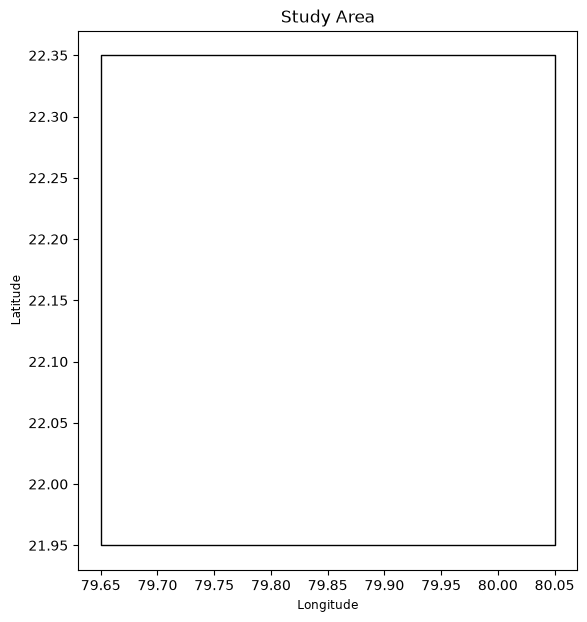

In [3]:
# Visual check of the study area
ax = study_area.plot(figsize=(8, 7), edgecolor="black", facecolor="none")
ax.set_title("Study Area")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()


## 2. Check environmental / space-technology conditions

In [4]:
environment = load_csv(
    "synthetic_environmental.csv",
    parse_dates=["date"],
)

required_env = {
    "date", "zone", "rainfall_mm", "soil_moisture",
    "ndvi", "land_temperature_c"
}
missing_env = required_env - set(environment.columns)
if missing_env:
    raise ValueError(f"Environmental CSV is missing columns: {sorted(missing_env)}")

print(environment.head())
print("\nCoverage:")
print("Dates:", environment["date"].min().date(), "to", environment["date"].max().date())
print("Zones:", sorted(environment["zone"].unique()))

env_summary = (
    environment.groupby("zone")
    .agg(
        avg_rainfall_mm=("rainfall_mm", "mean"),
        max_rainfall_mm=("rainfall_mm", "max"),
        avg_soil_moisture=("soil_moisture", "mean"),
        avg_ndvi=("ndvi", "mean"),
        avg_land_temperature_c=("land_temperature_c", "mean"),
    )
    .round(3)
)

print("\nEnvironmental summary by zone:")
display(env_summary)


        date    zone  rainfall_mm  soil_moisture    ndvi  land_temperature_c
0 2024-08-01  Zone_A        44.15         0.4663  0.6212               29.14
1 2024-08-02  Zone_A        47.47         0.4252  0.6218               28.46
2 2024-08-03  Zone_A        51.15         0.4673  0.6189               29.73
3 2024-08-04  Zone_A        56.88         0.4944  0.6083               26.80
4 2024-08-05  Zone_A        55.22         0.5362  0.6278               28.17

Coverage:
Dates: 2024-08-01 to 2025-01-27
Zones: ['Zone_A', 'Zone_B', 'Zone_C', 'Zone_D']

Environmental summary by zone:


,avg_rainfall_mm,max_rainfall_mm,avg_soil_moisture,avg_ndvi,avg_land_temperature_c
zone,,,,,
Zone_A,26.042,135.03,0.360,0.561,30.077
Zone_B,28.175,126.83,0.367,0.552,29.994
Zone_C,28.099,146.62,0.366,0.549,30.970
Zone_D,31.357,125.33,0.367,0.544,31.110


In [5]:
# Latest 7-day environmental condition and a transparent risk flag.
latest_env_date = environment["date"].max()
env_7d = (
    environment[environment["date"] > latest_env_date - pd.Timedelta(days=7)]
    .groupby("zone")
    .agg(
        rainfall_7d_mm=("rainfall_mm", "mean"),
        soil_moisture_7d=("soil_moisture", "mean"),
        ndvi_7d=("ndvi", "mean"),
        land_temperature_7d_c=("land_temperature_c", "mean"),
    )
)

def environmental_risk(row):
    reasons = []
    score = 0.0

    if row["rainfall_7d_mm"] >= 35:
        score += 0.45
        reasons.append("elevated rainfall")
    if row["soil_moisture_7d"] >= 0.48:
        score += 0.30
        reasons.append("high soil moisture")
    if row["land_temperature_7d_c"] >= 36:
        score += 0.25
        reasons.append("high land temperature")

    if score >= 0.60:
        level = "HIGH"
    elif score >= 0.30:
        level = "MEDIUM"
    else:
        level = "LOW"

    return pd.Series({
        "environment_risk_score": round(min(score, 1.0), 3),
        "environment_risk": level,
        "environment_reasons": ", ".join(reasons) if reasons else "normal environmental conditions",
    })

env_check = env_7d.apply(environmental_risk, axis=1)
env_check = env_7d.join(env_check)

print("Latest environmental check:")
display(env_check.round(3))


Latest environmental check:


,rainfall_7d_mm,soil_moisture_7d,ndvi_7d,land_temperature_7d_c,environment_risk_score,environment_risk,environment_reasons
zone,,,,,,,
Zone_A,42.357,0.506,0.533,28.436,0.75,HIGH,"elevated rainfall, high soil moisture"
Zone_B,40.390,0.428,0.590,28.846,0.45,MEDIUM,elevated rainfall
Zone_C,41.714,0.413,0.583,29.911,0.45,MEDIUM,elevated rainfall
Zone_D,53.484,0.428,0.578,30.994,0.45,MEDIUM,elevated rainfall


## 3. Check equipment performance

In [6]:
equipment = load_csv(
    "synthetic_equipment.csv",
    parse_dates=["date"],
)

required_eq = {
    "date", "zone", "equipment_id", "equipment_type",
    "hours_available", "hours_operated", "downtime_hours",
    "maintenance_hours", "availability_pct", "utilization_pct"
}
missing_eq = required_eq - set(equipment.columns)
if missing_eq:
    raise ValueError(f"Equipment CSV is missing columns: {sorted(missing_eq)}")

latest_eq_date = equipment["date"].max()
eq_7d = equipment[equipment["date"] > latest_eq_date - pd.Timedelta(days=7)]

equipment_summary = (
    eq_7d.groupby("zone")
    .agg(
        downtime_hours_7d=("downtime_hours", "sum"),
        maintenance_hours_7d=("maintenance_hours", "sum"),
        availability_7d=("availability_pct", "mean"),
        utilization_7d=("utilization_pct", "mean"),
        equipment_units=("equipment_id", "nunique"),
    )
    .round(3)
)

print("Equipment condition — recent 7 days:")
display(equipment_summary)

def equipment_risk(row):
    reasons = []
    score = 0.0

    if row["availability_7d"] < 0.75:
        score += 0.55
        reasons.append("low equipment availability")
    elif row["availability_7d"] < 0.85:
        score += 0.30
        reasons.append("reduced equipment availability")

    if row["downtime_hours_7d"] > 60:
        score += 0.45
        reasons.append("high downtime")
    elif row["downtime_hours_7d"] > 35:
        score += 0.25
        reasons.append("elevated downtime")

    if score >= 0.70:
        level = "HIGH"
    elif score >= 0.30:
        level = "MEDIUM"
    else:
        level = "LOW"

    return pd.Series({
        "equipment_risk_score": round(min(score, 1.0), 3),
        "equipment_risk": level,
        "equipment_reasons": ", ".join(reasons) if reasons else "equipment condition normal",
    })

equipment_check = equipment_summary.join(
    equipment_summary.apply(equipment_risk, axis=1)
)

display(equipment_check)


Equipment condition — recent 7 days:


,downtime_hours_7d,maintenance_hours_7d,availability_7d,utilization_7d,equipment_units
zone,,,,,
Zone_A,250.01,0,0.517,0.430,3
Zone_B,264.99,0,0.476,0.351,3
Zone_C,245.52,6,0.513,0.422,3
Zone_D,255.59,4,0.498,0.398,3


,downtime_hours_7d,maintenance_hours_7d,availability_7d,utilization_7d,equipment_units,equipment_risk_score,equipment_risk,equipment_reasons
zone,,,,,,,,
Zone_A,250.01,0,0.517,0.430,3,1.0,HIGH,"low equipment availability, high downtime"
Zone_B,264.99,0,0.476,0.351,3,1.0,HIGH,"low equipment availability, high downtime"
Zone_C,245.52,6,0.513,0.422,3,1.0,HIGH,"low equipment availability, high downtime"
Zone_D,255.59,4,0.498,0.398,3,1.0,HIGH,"low equipment availability, high downtime"


In [7]:
# Identify equipment with the largest recent downtime so the recommendation
# engine can propose a specific unit for maintenance/redeployment.
equipment_unit_summary = (
    eq_7d.groupby(["zone", "equipment_id", "equipment_type"])
    .agg(
        downtime_hours=("downtime_hours", "sum"),
        availability=("availability_pct", "mean"),
        utilization=("utilization_pct", "mean"),
    )
    .sort_values(["zone", "downtime_hours"], ascending=[True, False])
    .round(3)
)

print("Equipment units ranked by recent downtime:")
display(equipment_unit_summary.head(20))


Equipment units ranked by recent downtime:


downtime_hours  availability  utilization
zone   equipment_id equipment_type                                           
Zone_A A_EX01       Excavator                95.93         0.470        0.351
       A_HD01       Haul_Dumper              89.69         0.456        0.410
       A_DR01       Drill_Rig                64.39         0.626        0.528
Zone_B B_HD01       Haul_Dumper             108.23         0.364        0.244
       B_EX01       Excavator                89.85         0.465        0.339
       B_DR01       Drill_Rig                66.91         0.600        0.469
Zone_C C_HD01       Haul_Dumper              94.57         0.439        0.318
       C_EX01       Excavator                88.77         0.479        0.430
       C_DR01       Drill_Rig                62.18         0.620        0.519
Zone_D D_HD01       Haul_Dumper              98.75         0.417        0.295
       D_EX01       Excavator                93.51         0.454        0.404
       D_DR01       Drill_Rig                63.33         0.624        0.495

## 4. Check blasting delays

In [8]:
blasting = load_csv(
    "synthetic_blasting.csv",
    parse_dates=["date"],
)

required_blast = {
    "blast_id", "date", "zone", "delay_hours",
    "planned_ore_tonnes", "actual_ore_tonnes", "blast_efficiency_pct"
}
missing_blast = required_blast - set(blasting.columns)
if missing_blast:
    raise ValueError(f"Blasting CSV is missing columns: {sorted(missing_blast)}")

blast_30d = blasting[
    blasting["date"] > blasting["date"].max() - pd.Timedelta(days=30)
]

blast_summary = (
    blast_30d.groupby("zone")
    .agg(
        blast_count_30d=("blast_id", "count"),
        avg_delay_hours=("delay_hours", "mean"),
        max_delay_hours=("delay_hours", "max"),
        total_delay_hours=("delay_hours", "sum"),
        avg_blast_efficiency_pct=("blast_efficiency_pct", "mean"),
        planned_ore_tonnes=("planned_ore_tonnes", "sum"),
        actual_ore_tonnes=("actual_ore_tonnes", "sum"),
    )
)

blast_summary["ore_gap_tonnes"] = (
    blast_summary["planned_ore_tonnes"] -
    blast_summary["actual_ore_tonnes"]
)

blast_summary = blast_summary.round(2)

print("Blasting summary — recent 30 days:")
display(blast_summary)

def blasting_risk(row):
    reasons = []
    score = 0.0

    if row["avg_delay_hours"] >= 2.5:
        score += 0.60
        reasons.append("high average blast delay")
    elif row["avg_delay_hours"] >= 1.5:
        score += 0.35
        reasons.append("elevated blast delay")

    if row["avg_blast_efficiency_pct"] < 90:
        score += 0.40
        reasons.append("low blast efficiency")

    if score >= 0.70:
        level = "HIGH"
    elif score >= 0.30:
        level = "MEDIUM"
    else:
        level = "LOW"

    return pd.Series({
        "blast_risk_score": round(min(score, 1.0), 3),
        "blast_risk": level,
        "blast_reasons": ", ".join(reasons) if reasons else "blasting performance normal",
    })

blast_check = blast_summary.join(blast_summary.apply(blasting_risk, axis=1))
display(blast_check)


Blasting summary — recent 30 days:


,blast_count_30d,avg_delay_hours,max_delay_hours,total_delay_hours,avg_blast_efficiency_pct,planned_ore_tonnes,actual_ore_tonnes,ore_gap_tonnes
zone,,,,,,,,
Zone_A,10,1.73,3.14,17.27,90.58,3755.05,3346.96,408.09
Zone_B,11,2.92,9.16,32.08,89.34,4729.97,4224.35,505.62
Zone_C,11,2.24,4.49,24.64,89.49,4438.61,4032.00,406.61
Zone_D,10,3.36,10.62,33.65,93.24,4156.98,3861.91,295.07


,blast_count_30d,avg_delay_hours,max_delay_hours,total_delay_hours,avg_blast_efficiency_pct,planned_ore_tonnes,actual_ore_tonnes,ore_gap_tonnes,blast_risk_score,blast_risk,blast_reasons
zone,,,,,,,,,,,
Zone_A,10,1.73,3.14,17.27,90.58,3755.05,3346.96,408.09,0.35,MEDIUM,elevated blast delay
Zone_B,11,2.92,9.16,32.08,89.34,4729.97,4224.35,505.62,1.00,HIGH,"high average blast delay, low blast efficiency"
Zone_C,11,2.24,4.49,24.64,89.49,4438.61,4032.00,406.61,0.75,HIGH,"elevated blast delay, low blast efficiency"
Zone_D,10,3.36,10.62,33.65,93.24,4156.98,3861.91,295.07,0.60,MEDIUM,high average blast delay


## 5. Load production targets and historical production

In [9]:
targets = load_csv(
    "synthetic_production_targets.csv",
    parse_dates=["date"],
)

required_targets = {
    "date", "zone", "planned_production_tonnes", "minimum_required_tonnes"
}
missing_targets = required_targets - set(targets.columns)
if missing_targets:
    raise ValueError(f"Production target CSV is missing columns: {sorted(missing_targets)}")

# Use the project's existing historical production data when available.
# If it is missing, make a clearly-labelled synthetic fallback from the target
# and operational constraints so the notebook can still demonstrate the flow.
production_path = DATA_DIR / "synthetic_production.csv"

if production_path.exists():
    production = load_csv("synthetic_production.csv", parse_dates=["date"])
    production_source = "existing synthetic_production.csv"
else:
    op = load_csv("synthetic_operational_features.csv", parse_dates=["date"])

    # Transparent prototype fallback — not suitable for real production use.
    disruption = (
        0.0009 * op["equipment_downtime_hours"] +
        0.025 * op["blast_delay_hours"] +
        0.0015 * op["rainfall_mm"] +
        0.12 * op["soil_moisture"]
    )
    noise = np.random.default_rng(42).normal(0, 12, len(op))

    production = targets.merge(op, on=["date", "zone"], how="left")
    production["production_tonnes"] = (
        production["planned_production_tonnes"] * (1 - disruption) + noise
    ).clip(lower=0)

    production["rainfall_mm"] = production["rainfall_mm"]
    production["maintenance_downtime"] = (
        production["equipment_downtime_hours"] > 10
    ).astype(int)

    production = production[
        ["date", "zone", "production_tonnes",
         "rainfall_mm", "maintenance_downtime"]
    ]
    production_source = "synthetic fallback derived from supplied operational CSVs"

print("Production source:", production_source)
print(production.head())
print("Coverage:", production["date"].min().date(), "to", production["date"].max().date())

latest_target = targets.sort_values("date").groupby("zone").tail(1).set_index("zone")
print("\nLatest production targets:")
display(latest_target[["date", "planned_production_tonnes", "minimum_required_tonnes"]])


Production source: synthetic fallback derived from supplied operational CSVs
        date    zone  production_tonnes  rainfall_mm  maintenance_downtime
0 2024-08-01  Zone_A         316.204196        46.43                     1
1 2024-08-02  Zone_A         308.444082        47.07                     1
2 2024-08-03  Zone_A         337.013199        47.25                     1
3 2024-08-04  Zone_A         338.295192        56.35                     1
4 2024-08-05  Zone_A         314.822478        57.71                     1
Coverage: 2024-08-01 to 2025-01-27

Latest production targets:


,date,planned_production_tonnes,minimum_required_tonnes
zone,,,
Zone_B,2025-01-27,416.12,373.99
Zone_A,2025-01-27,397.27,357.38
Zone_C,2025-01-27,386.41,347.14
Zone_D,2025-01-27,420.47,379.22


## 6. Integrate environment + equipment + blasting + target + production

In [10]:
# The supplied operational_features CSV already contains the daily zone-level
# environmental/equipment/blasting aggregates. We still merge the individual
# files above so that every stage can be audited independently.
operational = load_csv(
    "synthetic_operational_features.csv",
    parse_dates=["date"],
)

dataset = (
    production[["date", "zone", "production_tonnes"]]
    .merge(operational, on=["date", "zone"], how="left")
    .merge(
        targets[["date", "zone", "planned_production_tonnes", "minimum_required_tonnes"]],
        on=["date", "zone"],
        how="left",
    )
)

# Make the prediction target: next-day production.
dataset = dataset.sort_values(["zone", "date"]).reset_index(drop=True)
dataset["next_day_production_tonnes"] = (
    dataset.groupby("zone")["production_tonnes"].shift(-1)
)

# Historical features
dataset["production_lag_1"] = dataset.groupby("zone")["production_tonnes"].shift(1)
dataset["production_lag_3"] = dataset.groupby("zone")["production_tonnes"].shift(3)
dataset["production_lag_7"] = dataset.groupby("zone")["production_tonnes"].shift(7)
dataset["production_rolling_7d"] = (
    dataset.groupby("zone")["production_tonnes"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

print("Integrated dataset shape:", dataset.shape)
display(dataset.head())


Integrated dataset shape: (720, 23)


,date,zone,production_tonnes,rainfall_mm,soil_moisture,ndvi,land_temperature_c,equipment_downtime_hours,maintenance_hours,equipment_availability_pct,...,blast_planned_ore_tonnes,blast_actual_ore_tonnes,planned_production_tonnes_base,planned_production_tonnes,minimum_required_tonnes,next_day_production_tonnes,production_lag_1,production_lag_3,production_lag_7,production_rolling_7d
0,2024-08-01,Zone_A,316.204196,46.43,0.4497,0.6077,29.34,43.63,6.0,0.3879,...,498.77,446.12,400,400.51,361.72,308.444082,NaN,NaN,NaN,NaN
1,2024-08-02,Zone_A,308.444082,47.07,0.4241,0.6154,28.13,39.78,0.0,0.4389,...,20.78,0.00,400,399.40,361.20,337.013199,316.204196,NaN,NaN,NaN
2,2024-08-03,Zone_A,337.013199,47.25,0.4619,0.6309,29.72,26.00,0.0,0.6278,...,0.00,5.66,400,402.06,363.30,338.295192,308.444082,NaN,NaN,NaN
3,2024-08-04,Zone_A,338.295192,56.35,0.5250,0.6077,27.21,36.47,0.0,0.5090,...,0.00,0.00,400,404.97,362.67,314.822478,337.013199,316.204196,NaN,NaN
4,2024-08-05,Zone_A,314.822478,57.71,0.5245,0.6241,27.97,34.48,0.0,0.5073,...,328.15,326.28,400,401.37,364.29,300.131686,338.295192,308.444082,NaN,NaN


## 7. Predict next-day production and production shortfall

In [11]:
prediction_features = [
    "production_lag_1",
    "production_lag_3",
    "production_lag_7",
    "production_rolling_7d",
    "rainfall_mm",
    "soil_moisture",
    "ndvi",
    "land_temperature_c",
    "equipment_downtime_hours",
    "maintenance_hours",
    "equipment_availability_pct",
    "equipment_utilization_pct",
    "blast_count",
    "blast_delay_hours",
    "blast_actual_ore_tonnes",
    "planned_production_tonnes",
]

model_df = dataset.dropna(
    subset=prediction_features + ["next_day_production_tonnes"]
).copy()

# Chronological split: last 20% of dates is the test period.
unique_dates = sorted(model_df["date"].unique())
cut_idx = max(1, int(len(unique_dates) * 0.80))
cut_date = unique_dates[cut_idx]

train_df = model_df[model_df["date"] < cut_date].copy()
test_df = model_df[model_df["date"] >= cut_date].copy()

X_train = train_df[prediction_features]
y_train = train_df["next_day_production_tonnes"]

X_test = test_df[prediction_features]
y_test = test_df["next_day_production_tonnes"]

production_model = xgb.XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.04,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="reg:squarederror",
    eval_metric="mae",
    random_state=42,
)

production_model.fit(X_train, y_train)

test_pred = production_model.predict(X_test)

mae = mean_absolute_error(y_test, test_pred)
rmse = mean_squared_error(y_test, test_pred) ** 0.5
r2 = r2_score(y_test, test_pred)

print(f"Chronological holdout starts: {pd.Timestamp(cut_date).date()}")
print(f"MAE  : {mae:.2f} tonnes/day")
print(f"RMSE : {rmse:.2f} tonnes/day")
print(f"R²   : {r2:.3f}")


Chronological holdout starts: 2024-12-23
MAE  : 21.07 tonnes/day
RMSE : 27.67 tonnes/day
R²   : 0.237


In [12]:
# Predict the next production day for each zone using the latest available row.
latest_rows = (
    dataset.sort_values("date")
    .groupby("zone")
    .tail(1)
    .copy()
)

# If the very last row lacks lag features, use the last model-ready row for that zone.
for zone in latest_rows["zone"]:
    row = latest_rows.loc[latest_rows["zone"] == zone].iloc[0]
    if row[prediction_features].isna().any():
        replacement = model_df[model_df["zone"] == zone].sort_values("date").tail(1).iloc[0]
        latest_rows.loc[latest_rows["zone"] == zone, prediction_features] = replacement[prediction_features].values

latest_rows["predicted_next_day_tonnes"] = production_model.predict(
    latest_rows[prediction_features]
)

latest_rows["planned_tonnes"] = latest_rows["planned_production_tonnes"]
latest_rows["minimum_required_tonnes"] = latest_rows["minimum_required_tonnes"]

latest_rows["shortfall_tonnes"] = (
    latest_rows["planned_tonnes"] -
    latest_rows["predicted_next_day_tonnes"]
).clip(lower=0)

latest_rows["shortfall_pct"] = (
    latest_rows["shortfall_tonnes"] /
    latest_rows["planned_tonnes"].replace(0, np.nan) * 100
).fillna(0)

def risk_label(pct):
    if pct >= 15:
        return "HIGH"
    if pct >= 5:
        return "MEDIUM"
    return "LOW"

latest_rows["shortfall_risk"] = latest_rows["shortfall_pct"].apply(risk_label)

prediction_summary = latest_rows[
    [
        "zone", "date", "predicted_next_day_tonnes", "planned_tonnes",
        "minimum_required_tonnes", "shortfall_tonnes",
        "shortfall_pct", "shortfall_risk"
    ]
].sort_values("shortfall_pct", ascending=False)

print("Next-day production / shortfall prediction:")
display(prediction_summary.round(2))


Next-day production / shortfall prediction:


,zone,date,predicted_next_day_tonnes,planned_tonnes,minimum_required_tonnes,shortfall_tonnes,shortfall_pct,shortfall_risk
719,Zone_D,2025-01-27,323.929993,420.47,379.22,96.54,22.96,HIGH
179,Zone_A,2025-01-27,316.769989,397.27,357.38,80.50,20.26,HIGH
359,Zone_B,2025-01-27,354.519989,416.12,373.99,61.60,14.80,MEDIUM
539,Zone_C,2025-01-27,343.500000,386.41,347.14,42.91,11.10,MEDIUM


## 8. Explain the likely drivers of shortfall

In [13]:
# Transparent factor scores. These are decision-support indicators, not causal
# proof. They make it clear why an action was triggered.
env_driver = env_check[[
    "environment_risk_score", "environment_risk", "environment_reasons"
]]

eq_driver = equipment_check[[
    "equipment_risk_score", "equipment_risk", "equipment_reasons"
]]

blast_driver = blast_check[[
    "blast_risk_score", "blast_risk", "blast_reasons"
]]

risk_df = (
    prediction_summary.set_index("zone")
    .join(env_driver, how="left")
    .join(eq_driver, how="left")
    .join(blast_driver, how="left")
)

# Normalize the three operational/environment contributors into percentages.
driver_cols = [
    "equipment_risk_score",
    "blast_risk_score",
    "environment_risk_score",
]

driver_total = risk_df[driver_cols].sum(axis=1).replace(0, 1)
contribution_name = {
    "equipment_risk_score": "equipment_contribution_pct",
    "blast_risk_score": "blast_contribution_pct",
    "environment_risk_score": "environment_contribution_pct",
}
for col in driver_cols:
    risk_df[contribution_name[col]] = (
        risk_df[col] / driver_total * 100
    )

driver_view = risk_df[
    [
        "shortfall_risk", "shortfall_pct",
        "equipment_contribution_pct",
        "blast_contribution_pct",
        "environment_contribution_pct",
        "equipment_reasons", "blast_reasons", "environment_reasons",
    ]
].round(1)

display(driver_view)


,shortfall_risk,shortfall_pct,equipment_contribution_pct,blast_contribution_pct,environment_contribution_pct,equipment_reasons,blast_reasons,environment_reasons
zone,,,,,,,,
Zone_D,HIGH,23.0,48.8,29.3,22.0,"low equipment availability, high downtime",high average blast delay,elevated rainfall
Zone_A,HIGH,20.3,47.6,16.7,35.7,"low equipment availability, high downtime",elevated blast delay,"elevated rainfall, high soil moisture"
Zone_B,MEDIUM,14.8,40.8,40.8,18.4,"low equipment availability, high downtime","high average blast delay, low blast efficiency",elevated rainfall
Zone_C,MEDIUM,11.1,45.5,34.1,20.5,"low equipment availability, high downtime","elevated blast delay, low blast efficiency",elevated rainfall


## 9. Preventive measures / manager recommendations

In [14]:
def top_equipment_for_zone(zone):
    z = equipment_unit_summary[
        equipment_unit_summary.index.get_level_values("zone") == zone
    ]
    if z.empty:
        return None
    # Candidate for attention: highest downtime unit.
    return z.reset_index().sort_values("downtime_hours", ascending=False).iloc[0]

def make_recommendations(row, zone):
    actions = []

    # Production shortfall
    if row["shortfall_pct"] >= 15:
        actions.append(
            "Prioritize high-prospectivity ore blocks in the near-term mine schedule."
        )
    elif row["shortfall_pct"] >= 5:
        actions.append(
            "Review the next planning cycle and keep a production buffer."
        )

    # Equipment
    if row["equipment_risk"] == "HIGH":
        eq = top_equipment_for_zone(zone)
        if eq is not None:
            actions.append(
                f"Schedule preventive maintenance for {eq['equipment_id']} "
                f"and assess redeployment of available backup equipment."
            )
        else:
            actions.append(
                "Schedule preventive maintenance and review equipment allocation."
            )
    elif row["equipment_risk"] == "MEDIUM":
        actions.append(
            "Inspect high-downtime equipment before the next production cycle."
        )

    # Blasting
    if row["blast_risk"] == "HIGH":
        actions.append(
            "Re-plan blasting windows and verify drill/haulage readiness before the blast."
        )
    elif row["blast_risk"] == "MEDIUM":
        actions.append(
            "Review recent blast delays and prepare schedule slack for the next cycle."
        )

    # Environment
    if row["environment_risk"] == "HIGH":
        actions.append(
            "Adjust mine/haulage scheduling for the environmental risk window and maintain contingency capacity."
        )
    elif row["environment_risk"] == "MEDIUM":
        actions.append(
            "Monitor weather/environment conditions daily and keep a schedule buffer."
        )

    if not actions:
        actions.append(
            "Continue normal operations and monitor the next forecast update."
        )

    return actions

recommendation_rows = []

for zone, row in risk_df.iterrows():
    actions = make_recommendations(row, zone)

    recommendation_rows.append({
        "zone": zone,
        "shortfall_risk": row["shortfall_risk"],
        "shortfall_pct": round(row["shortfall_pct"], 1),
        "primary_equipment_risk": row["equipment_risk"],
        "blast_risk": row["blast_risk"],
        "environment_risk": row["environment_risk"],
        "recommended_actions": " | ".join(actions),
    })

recommendations = pd.DataFrame(recommendation_rows).sort_values(
    "shortfall_pct", ascending=False
)

display(recommendations)


,zone,shortfall_risk,shortfall_pct,primary_equipment_risk,blast_risk,environment_risk,recommended_actions
0,Zone_D,HIGH,23.0,HIGH,MEDIUM,MEDIUM,Prioritize high-prospectivity ore blocks in th...
1,Zone_A,HIGH,20.3,HIGH,MEDIUM,HIGH,Prioritize high-prospectivity ore blocks in th...
2,Zone_B,MEDIUM,14.8,HIGH,HIGH,MEDIUM,Review the next planning cycle and keep a prod...
3,Zone_C,MEDIUM,11.1,HIGH,HIGH,MEDIUM,Review the next planning cycle and keep a prod...


## 10. Reserve / prospectivity model using surface + sub-surface indicators

In [15]:
# Keep the original geological workflow, but extend it with the supplied
# sub-surface proxy fields from synthetic_reserve_grid_enhanced.csv.

reserve_grid = load_csv("synthetic_reserve_grid_enhanced.csv")

surface_features = [
    "elevation_m",
    "slope_deg",
    "ndvi",
    "iron_oxide_ratio",
    "fe_mn_swir_ratio",
    "alteration_index",
    "bare_ground_index",
]

subsurface_features = [
    "depth_to_ore_m",
    "ore_thickness_m",
    "bulk_density_t_m3",
    "mn_grade_pct",
]

enhanced_features = surface_features + subsurface_features

print("Enhanced reserve-grid columns available:")
print(enhanced_features)
print("\nGrid:", reserve_grid.shape)


Enhanced reserve-grid columns available:
['elevation_m', 'slope_deg', 'ndvi', 'iron_oxide_ratio', 'fe_mn_swir_ratio', 'alteration_index', 'bare_ground_index', 'depth_to_ore_m', 'ore_thickness_m', 'bulk_density_t_m3', 'mn_grade_pct']

Grid: (14400, 19)


In [16]:
# Train the reserve classifier when drill-hole labels are available.
# The spatial-block split avoids a random point split leaking nearby geology.
drill_path = DATA_DIR / "synthetic_drill_holes.csv"

if drill_path.exists():
    drill = load_csv("synthetic_drill_holes.csv")

    drill_gdf = gpd.GeoDataFrame(
        drill,
        geometry=gpd.points_from_xy(drill["lon"], drill["lat"]),
        crs="EPSG:4326",
    ).to_crs("EPSG:32644")

    grid_gdf = gpd.GeoDataFrame(
        reserve_grid,
        geometry=gpd.points_from_xy(
            reserve_grid["lon"], reserve_grid["lat"]
        ),
        crs="EPSG:4326",
    ).to_crs("EPSG:32644")

    training_gdf = gpd.sjoin_nearest(
        drill_gdf,
        grid_gdf,
        how="left",
        distance_col="distance_to_grid_m",
    )

    available_features = [
        f for f in enhanced_features if f in training_gdf.columns
    ]

    reserve_ml = training_gdf[
        available_features + ["mn_present"]
    ].dropna()

    X = reserve_ml[available_features]
    y = reserve_ml["mn_present"].astype(int)

    # Geographic block split
    training_gdf["spatial_block"] = (
        (training_gdf["lon_right"] > training_gdf["lon_right"].median()).astype(int)
        + 2 * (training_gdf["lat_right"] > training_gdf["lat_right"].median()).astype(int)
    )

    train_geo = training_gdf[training_gdf["spatial_block"] != 3].dropna(
        subset=available_features + ["mn_present"]
    )
    test_geo = training_gdf[training_gdf["spatial_block"] == 3].dropna(
        subset=available_features + ["mn_present"]
    )

    reserve_model = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.80,
        colsample_bytree=0.80,
        scale_pos_weight=(
            (train_geo["mn_present"] == 0).sum() /
            max((train_geo["mn_present"] == 1).sum(), 1)
        ),
        eval_metric="aucpr",
        random_state=42,
    )

    reserve_model.fit(
        train_geo[available_features],
        train_geo["mn_present"].astype(int),
    )

    reserve_prob = reserve_model.predict_proba(
        test_geo[available_features]
    )[:, 1]

    reserve_pred = (reserve_prob >= PROSPECTIVITY_THRESHOLD).astype(int)

    print("Reserve/prospectivity spatial holdout:")
    print(classification_report(
        test_geo["mn_present"], reserve_pred, zero_division=0
    ))

    # Retrain on all labeled points for the deployment/demo map.
    reserve_model.fit(
        reserve_ml[available_features],
        reserve_ml["mn_present"].astype(int),
    )

    reserve_grid["probability"] = reserve_model.predict_proba(
        reserve_grid[available_features]
    )[:, 1]

    reserve_grid["classification"] = np.where(
        reserve_grid["probability"] >= PROSPECTIVITY_THRESHOLD,
        "probable",
        "improbable",
    )

    reserve_grid["confidence_tier"] = pd.cut(
        reserve_grid["probability"],
        bins=[-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf],
        labels=["very_low", "low", "medium", "high", "very_high"],
    ).astype(str)

    print("Reserve map generated from drill-hole labels.")
else:
    # If drill labels are not present in the current working directory, use
    # an existing finalized prediction file when available; otherwise expose
    # the engineered evidence surface without pretending it is a trained
    # probability model.
    # Prefer the integrated reserve output from a previous run because it already
    # contains surface + sub-surface evidence and potential-tonnage fields.
    integrated = OUTPUT_DIR / "integrated_reserve_grid_predictions.csv"
    finalized = OUTPUT_DIR / "prospectivity_grid_predictions.csv"

    if integrated.exists():
        pred = load_csv("outputs/integrated_reserve_grid_predictions.csv")
        keep = [c for c in [
            "lon", "lat", "zone", "probability", "classification",
            "confidence_tier", "potential_ore_tonnes", "potential_mn_tonnes",
            "weighted_potential_ore_tonnes", "weighted_potential_mn_tonnes",
            "mn_grade_pct", "ore_thickness_m", "depth_to_ore_m"
        ] if c in pred.columns]
        reserve_grid = reserve_grid.merge(
            pred[keep],
            on=["lon", "lat"],
            how="left",
            suffixes=("", "_existing"),
        )
        for c in [
            "zone", "probability", "classification", "confidence_tier",
            "potential_ore_tonnes", "potential_mn_tonnes",
            "weighted_potential_ore_tonnes", "weighted_potential_mn_tonnes",
            "mn_grade_pct", "ore_thickness_m", "depth_to_ore_m"
        ]:
            existing = f"{c}_existing"
            if existing in reserve_grid.columns:
                if c in reserve_grid.columns:
                    reserve_grid[c] = reserve_grid[c].fillna(reserve_grid[existing])
                    reserve_grid.drop(columns=[existing], inplace=True)
                else:
                    reserve_grid.rename(columns={existing: c}, inplace=True)
        reserve_grid["confidence_tier"] = pd.cut(
            reserve_grid["probability"],
            bins=[-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf],
            labels=["very_low", "low", "medium", "high", "very_high"],
        ).astype(str)
        print("Loaded finalized prospectivity predictions.")
    elif finalized.exists():
        pred = load_csv("outputs/prospectivity_grid_predictions.csv")
        reserve_grid = reserve_grid.merge(
            pred[["lon", "lat", "probability", "classification"]],
            on=["lon", "lat"],
            how="left",
        )
        reserve_grid["confidence_tier"] = pd.cut(
            reserve_grid["probability"],
            bins=[-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf],
            labels=["very_low", "low", "medium", "high", "very_high"],
        ).astype(str)
        print("Loaded finalized prospectivity predictions.")
    else:
        # Evidence score for visualization only.
        reserve_grid["probability"] = (
            0.55 * reserve_grid["surface_evidence_score"] +
            0.45 * reserve_grid["subsurface_evidence_score"]
        ).clip(0, 1)

        reserve_grid["classification"] = np.where(
            reserve_grid["probability"] >= PROSPECTIVITY_THRESHOLD,
            "probable",
            "improbable",
        )

        reserve_grid["confidence_tier"] = pd.cut(
            reserve_grid["probability"],
            bins=[-np.inf, 0.20, 0.40, 0.60, 0.80, np.inf],
            labels=["very_low", "low", "medium", "high", "very_high"],
        ).astype(str)

        print(
            "No drill-hole model file found. Using surface+sub-surface evidence "
            "score for the prototype map, not a trained ML probability."
        )


Reserve/prospectivity spatial holdout:
              precision    recall  f1-score   support

           0       0.68      0.06      0.11       452
           1       0.27      0.92      0.42       170

    accuracy                           0.30       622
   macro avg       0.48      0.49      0.27       622
weighted avg       0.57      0.30      0.20       622

Reserve map generated from drill-hole labels.


## 11. Estimate potential ore by zone

In [17]:
# This is a prototype resource/potential-ore estimate.
# It is NOT a certified mineral reserve statement.
reserve_grid["weighted_potential_ore_tonnes"] = (
    reserve_grid["potential_ore_tonnes"] *
    reserve_grid["probability"]
)

reserve_grid["weighted_potential_mn_tonnes"] = (
    reserve_grid["potential_mn_tonnes"] *
    reserve_grid["probability"]
)

reserve_zone_summary = (
    reserve_grid.groupby("zone")
    .agg(
        grid_cells=("zone", "size"),
        probable_area_pct=(
            "classification",
            lambda s: (s == "probable").mean() * 100,
        ),
        weighted_potential_ore_tonnes=(
            "weighted_potential_ore_tonnes", "sum"
        ),
        weighted_potential_mn_tonnes=(
            "weighted_potential_mn_tonnes", "sum"
        ),
        avg_mn_grade_pct=("mn_grade_pct", "mean"),
        avg_ore_thickness_m=("ore_thickness_m", "mean"),
    )
    .round(2)
)

print("AI-estimated potential ore/resource indicator by zone:")
display(reserve_zone_summary)


AI-estimated potential ore/resource indicator by zone:


,grid_cells,probable_area_pct,weighted_potential_ore_tonnes,weighted_potential_mn_tonnes,avg_mn_grade_pct,avg_ore_thickness_m
zone,,,,,,
Zone_A,3600,96.81,4.137667e+09,1.074886e+09,24.03,6.95
Zone_B,3600,96.39,3.214253e+09,7.893554e+08,21.50,5.93
Zone_C,3600,96.81,2.789619e+09,5.867370e+08,19.58,5.16
Zone_D,3600,96.94,3.574514e+09,8.426881e+08,21.61,5.92


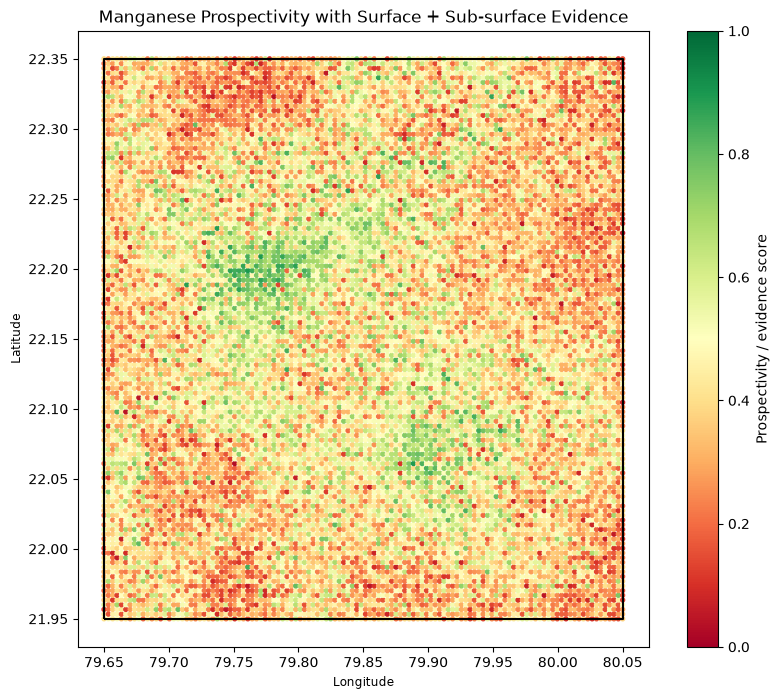

In [18]:
# Visualize the integrated reserve/prospectivity map.
fig, ax = plt.subplots(figsize=(10, 8))

sc = ax.scatter(
    reserve_grid["lon"],
    reserve_grid["lat"],
    c=reserve_grid["probability"],
    s=8,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
)

study_area.boundary.plot(ax=ax, color="black", linewidth=1.5)
plt.colorbar(sc, ax=ax, label="Prospectivity / evidence score")
ax.set_title("Manganese Prospectivity with Surface + Sub-surface Evidence")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()


## 12. Save outputs for FastAPI / dashboard

In [19]:
# Save all major outputs so FastAPI/dashboard can consume them later.

prediction_summary.to_csv(
    OUTPUT_DIR / "shortfall_predictions.csv",
    index=False,
)

recommendations.to_csv(
    OUTPUT_DIR / "preventive_recommendations.csv",
    index=False,
)

env_check.reset_index().to_csv(
    OUTPUT_DIR / "environment_zone_summary.csv",
    index=False,
)

equipment_check.reset_index().to_csv(
    OUTPUT_DIR / "equipment_zone_summary.csv",
    index=False,
)

blast_check.reset_index().to_csv(
    OUTPUT_DIR / "blasting_zone_summary.csv",
    index=False,
)

reserve_zone_summary.reset_index().to_csv(
    OUTPUT_DIR / "reserve_estimates_by_zone.csv",
    index=False,
)

reserve_grid[
    [
        "lon", "lat", "zone",
        "probability", "classification", "confidence_tier",
        "potential_ore_tonnes", "potential_mn_tonnes",
        "weighted_potential_ore_tonnes",
        "weighted_potential_mn_tonnes",
        "mn_grade_pct", "ore_thickness_m",
        "depth_to_ore_m"
    ]
].to_csv(
    OUTPUT_DIR / "integrated_reserve_grid_predictions.csv",
    index=False,
)

# Full operational history for the dashboard (not only the latest prediction).
dataset.to_csv(
    OUTPUT_DIR / "production_history_dashboard.csv",
    index=False,
)

# Save the trained production model and its evaluation metrics so the FastAPI
# backend can verify/load the actual model artifact rather than only serving CSVs.
production_model.save_model(str(OUTPUT_DIR / "production_model.json"))

with open(OUTPUT_DIR / "production_model_metrics.json", "w") as f:
    json.dump(
        {
            "chronological_test_start": str(pd.Timestamp(cut_date).date()),
            "mae_tonnes_per_day": float(mae),
            "rmse_tonnes_per_day": float(rmse),
            "r2": float(r2),
            "prediction_features": prediction_features,
        },
        f,
        indent=2,
    )

# Save the operational model feature importance.
production_importance = (
    pd.Series(
        production_model.feature_importances_,
        index=prediction_features,
    )
    .sort_values(ascending=False)
)

production_importance.to_csv(
    OUTPUT_DIR / "production_model_feature_importance.csv",
    header=["importance"],
)

# Save study-area bounds for the API.
study_bounds = {
    "lon_min": float(reserve_grid["lon"].min()),
    "lon_max": float(reserve_grid["lon"].max()),
    "lat_min": float(reserve_grid["lat"].min()),
    "lat_max": float(reserve_grid["lat"].max()),
}
with open(OUTPUT_DIR / "study_area_bounds.json", "w") as f:
    json.dump(study_bounds, f, indent=2)

print("Saved deployment artifacts:")
for p in sorted(OUTPUT_DIR.glob("*")):
    print(" -", p.name)


Saved deployment artifacts:
 - blasting_zone_summary.csv
 - environment_zone_summary.csv
 - equipment_zone_summary.csv
 - integrated_reserve_grid_predictions.csv
 - preventive_recommendations.csv
 - production_history_dashboard.csv
 - production_model.json
 - production_model_feature_importance.csv
 - production_model_metrics.json
 - reserve_estimates_by_zone.csv
 - shortfall_predictions.csv
 - study_area_bounds.json


## Final decision flow

The resulting system now follows:

**Study area**
→ **Environmental check (rainfall, soil moisture, NDVI, land temperature)**
→ **Equipment check (downtime, availability, utilization)**
→ **Blast-delay check**
→ **Production target**
→ **Next-day production prediction**
→ **Quantified shortfall + risk**
→ **Driver analysis**
→ **Preventive manager recommendations**

In parallel:

**Geological/spectral + drill/sub-surface evidence**
→ **Manganese prospectivity**
→ **Potential ore/resource estimate by zone**

The Streamlit dashboard can consume the files in `outputs/` through FastAPI.
